### Notebook 6d — Final Evaluation of the Tuberculosis Case Study

> Evaluates the scenarios trained in Notebook 6c on two **real** test sets: the held-out part of Shenzhen (same hospital as the training data) and the whole Montgomery set (**external**, different hospital and scanner). Computes AUROC, AUPRC, recall, specificity, precision and F1 with **bootstrap confidence intervals**, compares each scenario with the real-only baseline (**paired** bootstrap), and repeats the synthetic-shortcut diagnostic.

**Inputs to attach**: the output(s) of Notebook 6c (`preds/*.csv.gz`, `runs_summary.csv`); attach **both sessions** of 6c (first: T1-T5, -bal; second: T6 and small doses) and the output of Notebook 6a (`cache_tb/test_index.csv`, `cache_tb/test_external_index.csv`). **No GPU and no Internet needed.**

**One run per classifier**: set `BACKBONE` in section 1 (`densenet` for the outputs of 6c, `resnet50` or `convnext_tiny` for those of 6e). Every architecture is compared with its own `T1`. Attach all the 6c / 6e outputs you have; the notebook picks the files of the chosen architecture.

**Differences from the pneumonia study (Notebook 5)**

* The data have **one image per patient**, so the bootstrap resamples images (no patient clusters).
* Prevalence is about 50 %, so **precision and AUPRC are not comparable with the pneumonia study** (there prevalence was 2-5 %). Compare scenarios *within* this notebook.
* The test sets are small (a few hundred images), so the intervals are wide. Read differences between scenarios together with their paired interval, not the point estimates alone.

**Definitions**: recall, specificity, precision and F1 use the threshold chosen on the real validation set in 6c (Youden), never tuned on test. Each scenario was trained with several seeds; every metric is computed per seed and averaged, and in each bootstrap replicate the same resampled test images are used for all scenarios (paired).

### 1. Configuration and Input Discovery

In [1]:
import os, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_curve
warnings.filterwarnings('ignore')

N_BOOT, SEED = 2000, 42
INPUT_ROOT, OUT = '/kaggle/input', Path('/kaggle/working/eval_tb'); OUT.mkdir(parents=True, exist_ok=True)
REF = 'T1'
BACKBONE = 'densenet'      # 'densenet' = Notebook 6c outputs (TorchXRayVision DenseNet-121); 'resnet50' or 'convnext_tiny' = Notebook 6e outputs. One run of this notebook per architecture.

NAMES = {'T1': 'Real only (baseline)', 'T2': 'DC-GAN only', 'T3': 'Real + DC-GAN pos.', 'T4': 'RoentGen-v2 only', 'T5': 'Real + RoentGen pos.',
         'T6': 'DC-GAN pre-train, real fine-tune', 'T3-bal': 'T3 + DC-GAN neg.', 'T5-bal': 'T5 + RoentGen neg.', 'T3-dose150': 'T3 with 150 syn. pos.', 'T3-dose300': 'T3 with 300 syn. pos.',
         'T5-dose150': 'T5 with 150 syn. pos.', 'T5-dose300': 'T5 with 300 syn. pos.'}
COLORS = {'T1': '#2a78d6', 'T2': '#eb6834', 'T3': '#1baf7a', 'T4': '#eda100', 'T5': '#e87ba4', 'T6': '#7a3b9e', 'T3-bal': '#4a3aa7', 'T5-bal': '#e34948'}
nm = lambda s: NAMES.get(s, s)

ALL = []
for cur, dirs, files in os.walk(INPUT_ROOT):
    dirs[:] = [d for d in dirs if d != 'images']
    ALL += [os.path.join(cur, f) for f in files]
find = lambda base: [p for p in ALL if os.path.basename(p) == base]
def bb_of(path):                                                            # backbone of a prediction file: '<scenario>@<backbone>_seed<k>.csv.gz' (6e) or '<scenario>_seed<k>.csv.gz' (6c = densenet)
    m = re.match(r'(.+?)(?:@(.+))?_seed\d+\.csv\.gz$', os.path.basename(path)); return m.group(2) or 'densenet'
PRED_FILES = sorted(p for p in ALL if re.search(r'_seed\d+\.csv\.gz$', p) and bb_of(p) == BACKBONE); assert PRED_FILES, f'no prediction files for BACKBONE={BACKBONE!r}: attach the output of Notebook 6c (densenet) or 6e (resnet50 / convnext_tiny)'
SUMMARIES = [p for p in ALL if re.match(r'runs_summary.*\.csv$', os.path.basename(p))]; assert SUMMARIES, 'runs_summary*.csv not found: attach the output of Notebook 6c / 6e'
IDX_T, IDX_E = find('test_index.csv'), find('test_external_index.csv'); assert IDX_T and IDX_E, 'attach the output of Notebook 6a (cache_tb/test_index.csv and test_external_index.csv)'
print(f'BACKBONE = {BACKBONE} | {len(PRED_FILES)} prediction files | {len(SUMMARIES)} summary file(s)'); print('test index:', IDX_T[0]); print('external index:', IDX_E[0])

BACKBONE = densenet | 30 prediction files | 4 summary file(s)
test index: /kaggle/input/notebooks/anamatemalas/06a-tb-data-preparation/cache_tb/test_index.csv
external index: /kaggle/input/notebooks/anamatemalas/06a-tb-data-preparation/cache_tb/test_external_index.csv


### 2. Labels and Predictions

Each prediction file has the probability of the trained classifier on the validation set, the two real test sets and the held-out synthetic normals. The labels come from the Notebook 6a index files.

In [2]:
LAB = {'test': pd.read_csv(IDX_T[0]).set_index('image').label, 'test_external': pd.read_csv(IDX_E[0]).set_index('image').label}
summ = pd.concat([pd.read_csv(p) for p in SUMMARIES], ignore_index=True)
if 'backbone' not in summ.columns: summ['backbone'] = 'densenet'
summ['backbone'] = summ['backbone'].fillna('densenet'); summ = summ[summ.backbone == BACKBONE].drop_duplicates(['scenario', 'seed'], keep='last')
THR = summ.set_index(['scenario', 'seed']).threshold.to_dict()

P = {}                                    # P[split][scenario] -> DataFrame (seeds x images)
SYN = {}                                  # SYN[scenario][generator] -> mean prob per seed on held-out synthetic normals
for f in PRED_FILES:
    m = re.match(r'(.+?)(?:@.+)?_seed(\d+)\.csv\.gz$', os.path.basename(f)); sc, sd = m.group(1), int(m.group(2))
    d = pd.read_csv(f)
    for sp in ('test', 'test_external'):
        x = d[d.split == sp].set_index('image').prob.reindex(LAB[sp].index)
        assert x.notna().all(), f'{f}: missing images in {sp}'
        P.setdefault(sp, {}).setdefault(sc, {})[sd] = x.values
    for g in ('dcgan', 'roentgen'):
        x = d[d.split == f'synneg_{g}'].prob
        if len(x): SYN.setdefault(sc, {}).setdefault(g, {})[sd] = x.values
SCEN = [s for s in NAMES if s in P['test']] + [s for s in P['test'] if s not in NAMES]
assert REF in SCEN, 'baseline T1 missing'
for sp in P:
    for sc in P[sp]: P[sp][sc] = pd.DataFrame(P[sp][sc]).T.sort_index()           # seeds x images
Y = {sp: LAB[sp].values.astype(int) for sp in LAB}
print({s: sorted(P['test'][s].index.tolist()) for s in SCEN}); print({sp: (len(Y[sp]), int(Y[sp].sum())) for sp in Y}, '(images, tuberculosis)')

{'T1': [0, 1, 2], 'T2': [0, 1, 2], 'T3': [0, 1, 2], 'T4': [0, 1, 2], 'T5': [0, 1, 2], 'T6': [0, 1, 2], 'T3-bal': [0, 1, 2], 'T5-bal': [0, 1, 2], 'T3-dose150': [0, 1, 2], 'T3-dose300': [0, 1, 2]}
{'test': (166, 84), 'test_external': (138, 58)} (images, tuberculosis)


### 3. Metrics with Bootstrap Confidence Intervals

In each of the 2,000 replicates the test images are resampled with replacement (stratified by class so both classes are always present). Every scenario is evaluated on the same replicate, so differences are paired.

In [3]:
def auroc(y, p):
    r = rankdata(p); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def metrics(y, p, thr):
    pred = p >= thr; tp = (pred & (y == 1)).sum(); fp = (pred & (y == 0)).sum(); fn = (~pred & (y == 1)).sum(); tn = (~pred & (y == 0)).sum()
    rec = tp / max(tp + fn, 1); spe = tn / max(tn + fp, 1); pre = tp / max(tp + fp, 1); f1 = 2 * pre * rec / max(pre + rec, 1e-9)
    return {'AUROC': auroc(y, p), 'AUPRC': average_precision_score(y, p), 'recall': rec, 'specificity': spe, 'precision': pre, 'F1': f1}

KEYS = ['AUROC', 'AUPRC', 'recall', 'specificity', 'precision', 'F1']
def seedmean(sp, sc, idx):
    # mean over seeds of every metric, on the images in idx
    out = [metrics(Y[sp][idx], P[sp][sc].loc[sd].values[idx], THR[(sc, sd)]) for sd in P[sp][sc].index]
    return {k: np.mean([o[k] for o in out]) for k in KEYS}

rng = np.random.default_rng(SEED); BOOT = {}; POINT = {}
for sp in ('test', 'test_external'):
    y = Y[sp]; i1, i0 = np.where(y == 1)[0], np.where(y == 0)[0]
    reps = [np.concatenate([rng.choice(i1, len(i1)), rng.choice(i0, len(i0))]) for _ in range(N_BOOT)]
    for sc in SCEN:
        POINT[(sp, sc)] = seedmean(sp, sc, np.arange(len(y)))
        BOOT[(sp, sc)] = pd.DataFrame([seedmean(sp, sc, r) for r in reps])
    print(sp, 'done')

rows = []
for sp in ('test', 'test_external'):
    for sc in SCEN:
        r = {'set': sp, 'scenario': sc, 'description': nm(sc), 'seeds': len(P[sp][sc])}
        for k in KEYS:
            lo, hi = BOOT[(sp, sc)][k].quantile([.025, .975]); r[k] = POINT[(sp, sc)][k]; r[k + '_lo'] = lo; r[k + '_hi'] = hi
        rows.append(r)
RES = pd.DataFrame(rows); RES.to_csv(OUT / 'tb_results_all_metrics.csv', index=False)
fmt = lambda r, k: f"{r[k]:.3f} [{r[k+'_lo']:.3f}, {r[k+'_hi']:.3f}]"
for sp, title in (('test', 'Test Shenzhen (internal)'), ('test_external', 'Test Montgomery (external)')):
    print('\n' + title); d = RES[RES.set == sp]
    print(pd.DataFrame({'scenario': d.scenario, **{k: d.apply(lambda r: fmt(r, k), axis=1) for k in KEYS}}).to_string(index=False))

test done
test_external done

Test Shenzhen (internal)
  scenario                AUROC                AUPRC               recall          specificity            precision                   F1
        T1 0.895 [0.844, 0.938] 0.912 [0.866, 0.950] 0.829 [0.750, 0.901] 0.833 [0.756, 0.907] 0.836 [0.773, 0.898] 0.833 [0.776, 0.884]
        T2 0.871 [0.816, 0.917] 0.858 [0.783, 0.931] 0.738 [0.651, 0.821] 0.874 [0.805, 0.931] 0.861 [0.798, 0.920] 0.793 [0.726, 0.848]
        T3 0.898 [0.848, 0.941] 0.908 [0.856, 0.951] 0.813 [0.730, 0.885] 0.866 [0.801, 0.927] 0.861 [0.803, 0.919] 0.837 [0.780, 0.887]
        T4 0.724 [0.659, 0.790] 0.773 [0.717, 0.830] 0.595 [0.516, 0.679] 0.736 [0.663, 0.809] 0.705 [0.641, 0.773] 0.643 [0.576, 0.708]
        T5 0.887 [0.836, 0.933] 0.902 [0.855, 0.943] 0.829 [0.758, 0.893] 0.817 [0.740, 0.890] 0.824 [0.767, 0.887] 0.826 [0.773, 0.875]
        T6 0.905 [0.857, 0.947] 0.907 [0.845, 0.957] 0.798 [0.722, 0.869] 0.882 [0.825, 0.931] 0.881 [0.830, 0.929] 0.834 [

### 4. Paired Comparison with the Baseline

Difference in AUROC between each scenario and `T1` in the same bootstrap replicates. An interval that excludes 0 means the difference is unlikely to be test-set sampling noise. "P(better)" is the share of replicates in which the scenario beats the baseline.

In [4]:
rows = []
for sp in ('test', 'test_external'):
    for sc in SCEN:
        if sc == REF: continue
        for k in ('AUROC', 'AUPRC', 'recall', 'specificity'):
            d = BOOT[(sp, sc)][k] - BOOT[(sp, REF)][k]; lo, hi = d.quantile([.025, .975])
            rows.append({'set': sp, 'scenario': sc, 'metric': k, 'diff': POINT[(sp, sc)][k] - POINT[(sp, REF)][k], 'lo': lo, 'hi': hi, 'P(better)': (d > 0).mean(), 'excludes_0': (lo > 0) or (hi < 0)})
DIFF = pd.DataFrame(rows); DIFF.to_csv(OUT / 'tb_paired_differences.csv', index=False)
for sp, title in (('test', 'Shenzhen (internal)'), ('test_external', 'Montgomery (external)')):
    d = DIFF[(DIFF.set == sp) & (DIFF.metric == 'AUROC')]
    print(f'\nAUROC difference vs {REF} - {title}')
    print(pd.DataFrame({'scenario': d.scenario, 'diff [95% CI]': d.apply(lambda r: f"{r['diff']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]", axis=1), 'P(better)': d['P(better)'].round(2), 'CI excludes 0': d.excludes_0}).to_string(index=False))


AUROC difference vs T1 - Shenzhen (internal)
  scenario           diff [95% CI]  P(better)  CI excludes 0
        T2 -0.024 [-0.057, +0.007]       0.07          False
        T3 +0.002 [-0.017, +0.022]       0.61          False
        T4 -0.171 [-0.244, -0.094]       0.00           True
        T5 -0.008 [-0.031, +0.015]       0.24          False
        T6 +0.010 [-0.012, +0.035]       0.79          False
    T3-bal +0.021 [-0.001, +0.044]       0.97          False
    T5-bal -0.012 [-0.034, +0.010]       0.16          False
T3-dose150 +0.005 [-0.009, +0.023]       0.75          False
T3-dose300 +0.007 [-0.010, +0.026]       0.77          False

AUROC difference vs T1 - Montgomery (external)
  scenario           diff [95% CI]  P(better)  CI excludes 0
        T2 +0.073 [+0.015, +0.134]       0.99           True
        T3 +0.035 [+0.008, +0.067]       0.99           True
        T4 -0.057 [-0.141, +0.029]       0.11          False
        T5 -0.108 [-0.200, -0.010]       0.01       

### 5. Figures

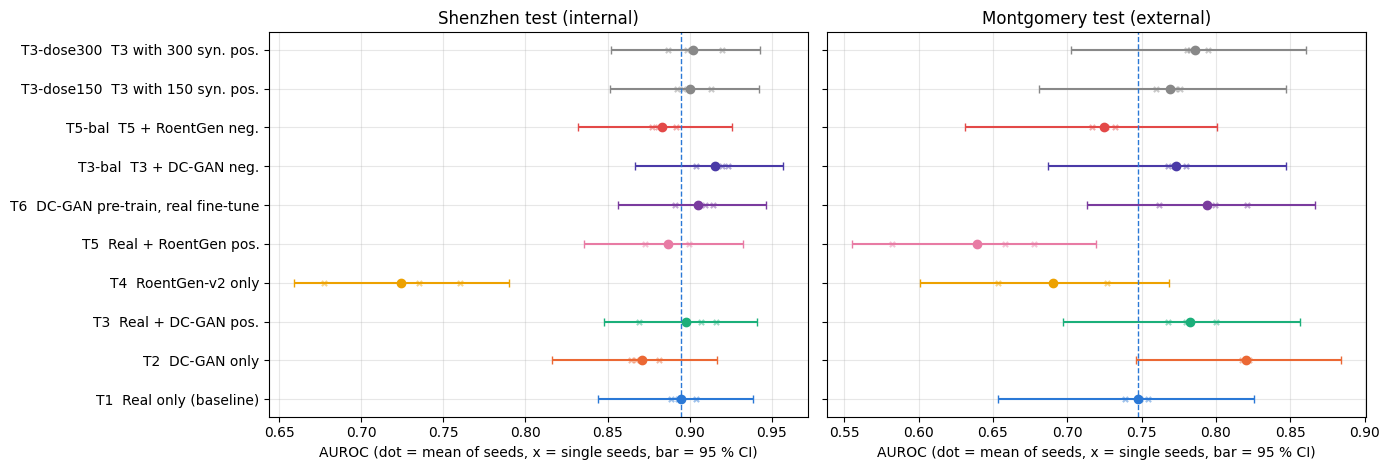

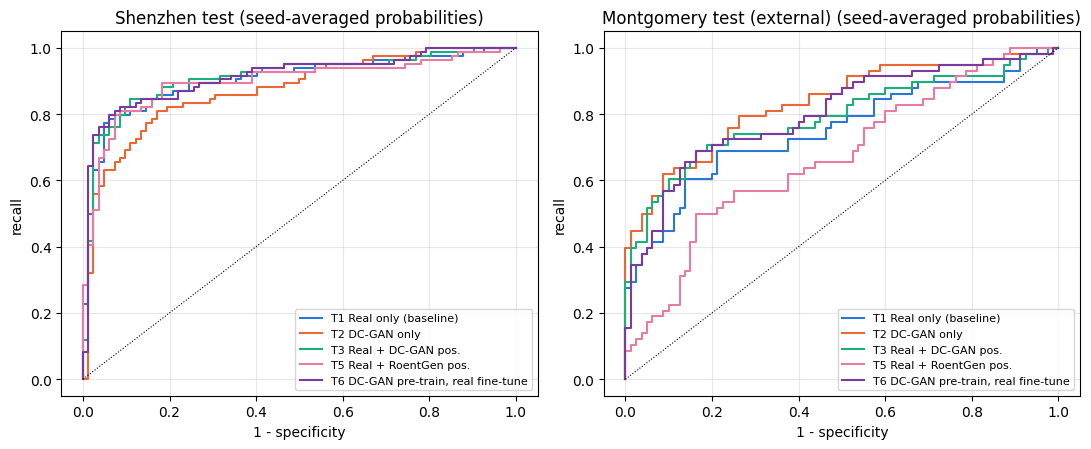

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, sp, title in zip(axs, ('test', 'test_external'), ('Shenzhen test (internal)', 'Montgomery test (external)')):
    d = RES[RES.set == sp].reset_index(drop=True)
    for i, r in d.iterrows():
        c = COLORS.get(r.scenario, '#888')
        ax.errorbar(r.AUROC, i, xerr=[[r.AUROC - r.AUROC_lo], [r.AUROC_hi - r.AUROC]], fmt='o', color=c, capsize=3)
        ax.scatter(P[sp][r.scenario].apply(lambda row: auroc(Y[sp], row.values), axis=1), [i] * len(P[sp][r.scenario]), s=14, color=c, alpha=.45, marker='x')
    ax.axvline(RES[(RES.set == sp) & (RES.scenario == REF)].AUROC.iloc[0], color='#2a78d6', ls='--', lw=1)
    ax.set_yticks(range(len(d))); ax.set_yticklabels([f'{s}  {nm(s)}' for s in d.scenario]); ax.invert_yaxis(); ax.set_title(title); ax.set_xlabel('AUROC (dot = mean of seeds, x = single seeds, bar = 95 % CI)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'tb_auroc_ci.png', dpi=150); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, sp, title in zip(axs, ('test', 'test_external'), ('Shenzhen test', 'Montgomery test (external)')):
    for sc in [s for s in ('T1', 'T2', 'T3', 'T5', 'T6') if s in SCEN]:
        p = P[sp][sc].mean(axis=0).values; fpr, tpr, _ = roc_curve(Y[sp], p); ax.plot(fpr, tpr, color=COLORS[sc], label=f'{sc} {nm(sc)}')
    ax.plot([0, 1], [0, 1], 'k:', lw=.8); ax.set_title(title + ' (seed-averaged probabilities)'); ax.set_xlabel('1 - specificity'); ax.set_ylabel('recall'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'tb_roc.png', dpi=150); plt.show()

### 6. Synthetic Shortcut Diagnostic

If a classifier trained with synthetic positives has learned "synthetic style = tuberculosis/normal" instead of the disease, its score on **held-out synthetic normal images** (never used in training) will differ strongly from its score on **real normal images**. The table gives the mean predicted probability of tuberculosis on real normal test images and on the held-out synthetic normals. A large gap shows the model separates real from synthetic. For scenarios with synthetic positives only (T3, T5) a **low** probability on synthetic normals is expected; the problem case is a value near 1 on RoentGen normals, meaning that RoentGen-style images are read as the positive class.

  scenario                      description  real normal (Shenzhen test)  real normal (Montgomery)  synthetic normal (dcgan)  synthetic normal (roentgen)
        T1             Real only (baseline)                        0.221                     0.211                     0.181                        0.195
        T2                      DC-GAN only                        0.205                     0.159                     0.009                        0.159
        T3               Real + DC-GAN pos.                        0.117                     0.136                     0.148                        0.111
        T4                 RoentGen-v2 only                        0.470                     0.341                     0.543                        0.385
        T5             Real + RoentGen pos.                        0.164                     0.906                     0.096                        0.979
        T6 DC-GAN pre-train, real fine-tune                        0.204    

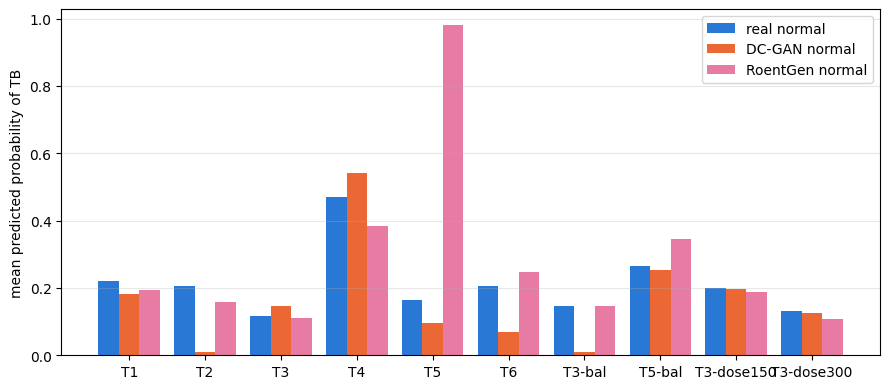

In [6]:
rows = []
for sc in SCEN:
    r = {'scenario': sc, 'description': nm(sc)}
    nr = np.mean([P['test'][sc].loc[sd].values[Y['test'] == 0].mean() for sd in P['test'][sc].index]); r['real normal (Shenzhen test)'] = nr
    nr2 = np.mean([P['test_external'][sc].loc[sd].values[Y['test_external'] == 0].mean() for sd in P['test_external'][sc].index]); r['real normal (Montgomery)'] = nr2
    for g in ('dcgan', 'roentgen'):
        v = SYN.get(sc, {}).get(g)
        r[f'synthetic normal ({g})'] = np.mean([x.mean() for x in v.values()]) if v else np.nan
    rows.append(r)
SH = pd.DataFrame(rows); SH.to_csv(OUT / 'tb_shortcut.csv', index=False); print(SH.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4)); x = np.arange(len(SH)); w = .27
ax.bar(x - w, SH['real normal (Shenzhen test)'], w, label='real normal', color='#2a78d6'); ax.bar(x, SH['synthetic normal (dcgan)'], w, label='DC-GAN normal', color='#eb6834'); ax.bar(x + w, SH['synthetic normal (roentgen)'], w, label='RoentGen normal', color='#e87ba4')
ax.set_xticks(x); ax.set_xticklabels(SH.scenario); ax.set_ylabel('mean predicted probability of TB'); ax.legend(); ax.grid(alpha=.3, axis='y'); plt.tight_layout(); plt.savefig(OUT / 'tb_shortcut.png', dpi=150); plt.show()

### 7. Variability Between Training Seeds

With this little data, the seed matters. The table gives the AUROC of each seed; if the ranges of two scenarios overlap heavily, treat the difference as inconclusive.

In [7]:
rows = []
for sp in ('test', 'test_external'):
    for sc in SCEN:
        a = P[sp][sc].apply(lambda r: auroc(Y[sp], r.values), axis=1)
        rows.append({'set': sp, 'scenario': sc, 'min': a.min(), 'mean': a.mean(), 'max': a.max(), 'sd': a.std(ddof=0)})
SV = pd.DataFrame(rows); SV.to_csv(OUT / 'tb_seed_variability.csv', index=False); print(SV.round(3).to_string(index=False))

          set   scenario   min  mean   max    sd
         test         T1 0.889 0.895 0.904 0.006
         test         T2 0.864 0.871 0.881 0.007
         test         T3 0.869 0.898 0.916 0.020
         test         T4 0.677 0.724 0.760 0.035
         test         T5 0.873 0.887 0.900 0.011
         test         T6 0.891 0.905 0.914 0.010
         test     T3-bal 0.904 0.916 0.923 0.008
         test     T5-bal 0.877 0.883 0.892 0.006
         test T3-dose150 0.892 0.900 0.913 0.009
         test T3-dose300 0.887 0.902 0.920 0.014
test_external         T1 0.739 0.747 0.754 0.006
test_external         T2 0.818 0.820 0.822 0.002
test_external         T3 0.768 0.783 0.800 0.013
test_external         T4 0.653 0.690 0.727 0.030
test_external         T5 0.582 0.639 0.678 0.041
test_external         T6 0.761 0.794 0.821 0.025
test_external     T3-bal 0.768 0.773 0.780 0.005
test_external     T5-bal 0.716 0.725 0.732 0.007
test_external T3-dose150 0.760 0.769 0.776 0.007
test_external T3-dos

### 8. Summary Table for the Thesis

In [8]:
t = RES.pivot(index='scenario', columns='set', values='AUROC').reindex(SCEN)
lo = RES.pivot(index='scenario', columns='set', values='AUROC_lo').reindex(SCEN); hi = RES.pivot(index='scenario', columns='set', values='AUROC_hi').reindex(SCEN)
dd = DIFF[DIFF.metric == 'AUROC'].pivot(index='scenario', columns='set', values='diff')
FIN = pd.DataFrame({'description': [nm(s) for s in SCEN],
                    'AUROC Shenzhen': [f"{t.loc[s,'test']:.3f} [{lo.loc[s,'test']:.3f}, {hi.loc[s,'test']:.3f}]" for s in SCEN],
                    'diff vs T1': [dd['test'].get(s, np.nan) for s in SCEN],
                    'AUROC Montgomery': [f"{t.loc[s,'test_external']:.3f} [{lo.loc[s,'test_external']:.3f}, {hi.loc[s,'test_external']:.3f}]" for s in SCEN],
                    'diff vs T1 (ext.)': [dd['test_external'].get(s, np.nan) for s in SCEN]}, index=SCEN)
FIN.to_csv(OUT / 'tb_summary_thesis.csv'); print(FIN.round(3).to_string())
print('\nFiles in', OUT, ':', sorted(os.listdir(OUT)))

                                 description        AUROC Shenzhen  diff vs T1      AUROC Montgomery  diff vs T1 (ext.)
T1                      Real only (baseline)  0.895 [0.844, 0.938]         NaN  0.747 [0.654, 0.826]                NaN
T2                               DC-GAN only  0.871 [0.816, 0.917]      -0.024  0.820 [0.746, 0.884]              0.073
T3                        Real + DC-GAN pos.  0.898 [0.848, 0.941]       0.002  0.783 [0.697, 0.856]              0.035
T4                          RoentGen-v2 only  0.724 [0.659, 0.790]      -0.171  0.690 [0.601, 0.769]             -0.057
T5                      Real + RoentGen pos.  0.887 [0.836, 0.933]      -0.008  0.639 [0.555, 0.719]             -0.108
T6          DC-GAN pre-train, real fine-tune  0.905 [0.857, 0.947]       0.010  0.794 [0.713, 0.867]              0.047
T3-bal                      T3 + DC-GAN neg.  0.916 [0.867, 0.957]       0.021  0.773 [0.687, 0.847]              0.026
T5-bal                    T5 + RoentGen 